In [1]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 고객 분석용 데이터 불러오기
rfm_data = pd.read_csv(
    "output/rfm_clean.csv",
    dtype={"CustomerID": str}
)

# 날짜 형식 변환
rfm_data["InvoiceDate"] = pd.to_datetime(
    rfm_data["InvoiceDate"]
)

print("데이터 크기:", rfm_data.shape)
print("전체 고객 수:", rfm_data["CustomerID"].nunique())

rfm_data.head()


데이터 크기: (392692, 9)
전체 고객 수: 4338


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Sales
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850,United Kingdom,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850,United Kingdom,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34


In [2]:

# 데이터 마지막 거래일 다음 날
snapshot_date = (
    rfm_data["InvoiceDate"].max()
    + pd.Timedelta(days=1)
)

print("분석 기준일:", snapshot_date)


분석 기준일: 2011-12-10 12:50:00


In [3]:

rfm = rfm_data.groupby("CustomerID").agg(
    Recency=("InvoiceDate",
             lambda x: (snapshot_date - x.max()).days),
    Frequency=("InvoiceNo", "nunique"),
    Monetary=("Sales", "sum")
)

rfm.head(10)


,Recency,Frequency,Monetary
CustomerID,,,
12346,326,1,77183.60
12347,2,7,4310.00
12348,75,4,1797.24
12349,19,1,1757.55
12350,310,1,334.40
12352,36,8,2506.04
12353,204,1,89.00
12354,232,1,1079.40
12355,214,1,459.40


In [4]:

rfm.describe().round(2)


,Recency,Frequency,Monetary
count,4338.00,4338.00,4338.00
mean,92.54,4.27,2048.69
std,100.01,7.70,8985.23
min,1.00,1.00,3.75
25%,18.00,1.00,306.48
50%,51.00,2.00,668.57
75%,142.00,5.00,1660.60
max,374.00,209.00,280206.02


In [5]:

# Recency 점수: 최근 구매 고객일수록 높은 점수
rfm["R_Score"] = pd.qcut(
    rfm["Recency"].rank(method="first"),
    5,
    labels=[5, 4, 3, 2, 1]
).astype(int)

# Frequency 점수: 구매 횟수가 많을수록 높은 점수
rfm["F_Score"] = pd.qcut(
    rfm["Frequency"].rank(method="first"),
    5,
    labels=[1, 2, 3, 4, 5]
).astype(int)

# Monetary 점수: 구매금액이 높을수록 높은 점수
rfm["M_Score"] = pd.qcut(
    rfm["Monetary"].rank(method="first"),
    5,
    labels=[1, 2, 3, 4, 5]
).astype(int)

rfm.head()


,Recency,Frequency,Monetary,R_Score,F_Score,M_Score
CustomerID,,,,,,
12346,326,1,77183.60,1,1,5
12347,2,7,4310.00,5,5,5
12348,75,4,1797.24,2,4,4
12349,19,1,1757.55,4,1,4
12350,310,1,334.40,1,1,2


In [6]:

# RFM 총점 계산
rfm["RFM_Score"] = (
    rfm["R_Score"]
    + rfm["F_Score"]
    + rfm["M_Score"]
)

# 점수가 높은 고객부터 확인
rfm.sort_values(
    "RFM_Score",
    ascending=False
).head(10)


,Recency,Frequency,Monetary,R_Score,F_Score,M_Score,RFM_Score
CustomerID,,,,,,,
18245,7,7,2567.06,5,5,5,15
18241,10,17,2073.09,5,5,5,15
18230,9,7,2810.20,5,5,5,15
18229,12,20,7276.90,5,5,5,15
18225,3,12,5504.96,5,5,5,15
18223,5,14,6484.54,5,5,5,15
18219,3,10,2069.77,5,5,5,15
18210,2,6,2621.38,5,5,5,15
18198,4,17,5425.56,5,5,5,15


In [7]:

def customer_segment(score):
    if score >= 13:
        return "VIP"
    elif score >= 10:
        return "High Value"
    elif score >= 7:
        return "Regular"
    else:
        return "Low Activity"

rfm["Segment"] = rfm["RFM_Score"].apply(
    customer_segment
)

rfm.head()


,Recency,Frequency,Monetary,R_Score,F_Score,M_Score,RFM_Score,Segment
CustomerID,,,,,,,,
12346,326,1,77183.60,1,1,5,7,Regular
12347,2,7,4310.00,5,5,5,15,VIP
12348,75,4,1797.24,2,4,4,10,High Value
12349,19,1,1757.55,4,1,4,9,Regular
12350,310,1,334.40,1,1,2,4,Low Activity


In [8]:

segment_count = rfm["Segment"].value_counts()

print(segment_count)


Segment
Low Activity    1312
Regular         1085
High Value      1012
VIP              929
Name: count, dtype: int64


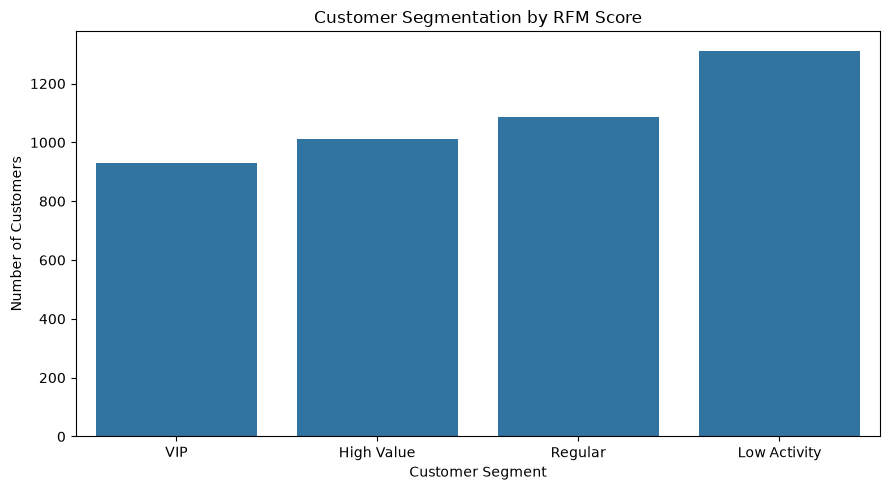

In [9]:

plt.figure(figsize=(9, 5))

sns.countplot(
    data=rfm,
    x="Segment",
    order=["VIP", "High Value", "Regular", "Low Activity"]
)

plt.title("Customer Segmentation by RFM Score")
plt.xlabel("Customer Segment")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()


In [10]:

# 고객 등급별 고객 수와 매출 합계
segment_analysis = rfm.groupby("Segment").agg(
    Customers=("Monetary", "count"),
    Total_Sales=("Monetary", "sum"),
    Avg_Sales=("Monetary", "mean")
)

segment_analysis.round(2)


,Customers,Total_Sales,Avg_Sales
Segment,,,
High Value,1012,1412579.34,1395.83
Low Activity,1312,366737.39,279.53
Regular,1085,878587.72,809.76
VIP,929,6229304.44,6705.39


In [11]:

# 전체 고객 대비 비중
segment_analysis["Customer_Ratio"] = (
    segment_analysis["Customers"]
    / segment_analysis["Customers"].sum() * 100
)

# 전체 고객 매출 대비 비중
segment_analysis["Sales_Ratio"] = (
    segment_analysis["Total_Sales"]
    / segment_analysis["Total_Sales"].sum() * 100
)

# 결과 확인
segment_analysis.round(2)


,Customers,Total_Sales,Avg_Sales,Customer_Ratio,Sales_Ratio
Segment,,,,,
High Value,1012,1412579.34,1395.83,23.33,15.89
Low Activity,1312,366737.39,279.53,30.24,4.13
Regular,1085,878587.72,809.76,25.01,9.89
VIP,929,6229304.44,6705.39,21.42,70.09


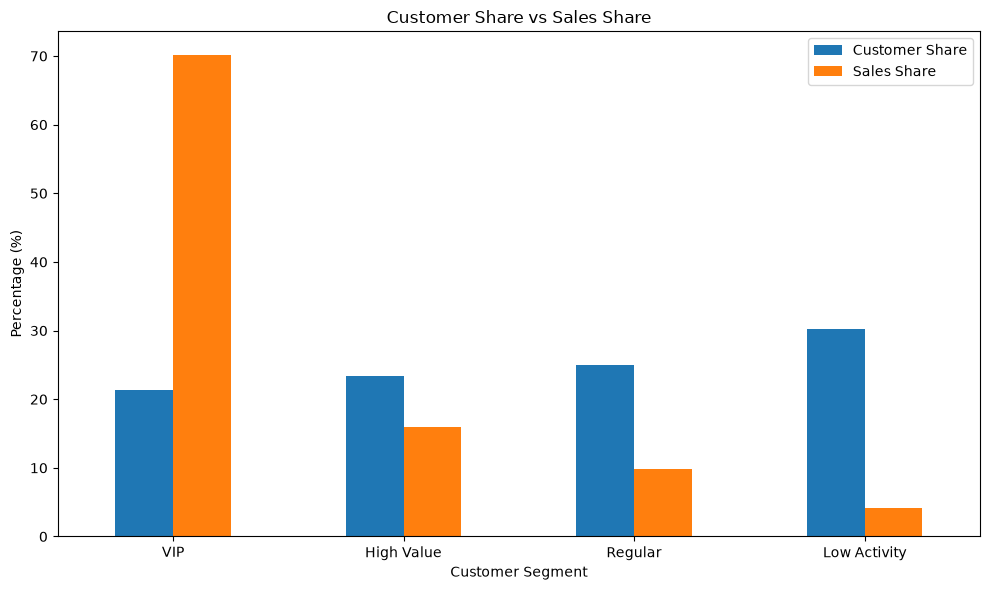

In [12]:

# 그래프에 표시할 순서
segment_order = [
    "VIP",
    "High Value",
    "Regular",
    "Low Activity"
]

plot_data = segment_analysis.loc[
    segment_order,
    ["Customer_Ratio", "Sales_Ratio"]
]

# 막대그래프
ax = plot_data.plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("Customer Share vs Sales Share")
plt.xlabel("Customer Segment")
plt.ylabel("Percentage (%)")
plt.xticks(rotation=0)
plt.legend(["Customer Share", "Sales Share"])
plt.tight_layout()
plt.show()


In [13]:

segment_analysis[
    ["Customers", "Avg_Sales", "Sales_Ratio"]
].loc[segment_order].round(2)


,Customers,Avg_Sales,Sales_Ratio
Segment,,,
VIP,929,6705.39,70.09
High Value,1012,1395.83,15.89
Regular,1085,809.76,9.89
Low Activity,1312,279.53,4.13


In [14]:

# 고객별 최근 구매 경과일 확인
rfm["Recency"].describe().round(2)


count    4338.00
mean       92.54
std       100.01
min         1.00
25%        18.00
50%        51.00
75%       142.00
max       374.00
Name: Recency, dtype: float64

In [15]:

# 최근 구매 경과일 기준 고객 구분
def activity_status(days):
    if days <= 30:
        return "Active"
    elif days <= 90:
        return "Attention"
    else:
        return "Inactive"

rfm["Activity_Status"] = rfm["Recency"].apply(
    activity_status
)

# 고객 수 확인
rfm["Activity_Status"].value_counts()


Activity_Status
Active       1648
Inactive     1449
Attention    1241
Name: count, dtype: int64

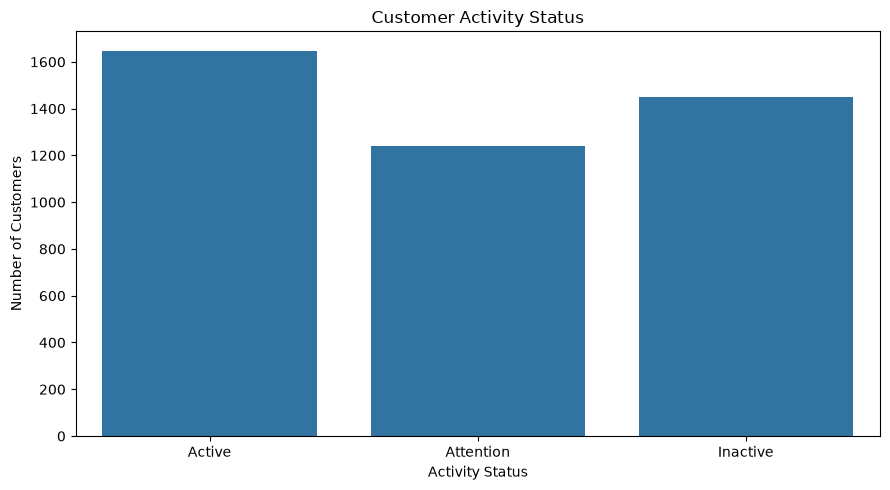

In [16]:

plt.figure(figsize=(9, 5))

sns.countplot(
    data=rfm,
    x="Activity_Status",
    order=["Active", "Attention", "Inactive"]
)

plt.title("Customer Activity Status")
plt.xlabel("Activity Status")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()


In [17]:

# VIP 중 최근 90일 넘게 구매하지 않은 고객
vip_inactive = rfm[
    (rfm["Segment"] == "VIP") &
    (rfm["Recency"] > 90)
]

print("장기간 미구매 VIP 고객 수:", len(vip_inactive))

vip_inactive.head()


장기간 미구매 VIP 고객 수: 0


,Recency,Frequency,Monetary,R_Score,F_Score,M_Score,RFM_Score,Segment,Activity_Status
CustomerID,,,,,,,,,


In [18]:

# 구매 빈도와 구매금액이 모두 높은 고객
rfm["High_Value_History"] = (
    (rfm["F_Score"] >= 4) &
    (rfm["M_Score"] >= 4)
)

print(
    "구매 실적 우수 고객:",
    rfm["High_Value_History"].sum()
)


구매 실적 우수 고객: 1360


In [19]:

# 구매 실적은 높지만 최근 구매하지 않은 고객
at_risk = rfm[
    (rfm["High_Value_History"]) &
    (rfm["Recency"] > 90)
].copy()

print("장기간 미구매 우수 고객 수:", len(at_risk))

at_risk[
    ["Recency", "Frequency", "Monetary",
     "F_Score", "M_Score"]
].head(10)


장기간 미구매 우수 고객 수: 115


,Recency,Frequency,Monetary,F_Score,M_Score
CustomerID,,,,,
12383,185,5,1850.56,4,4
12399,119,4,1108.65,4,4
12502,96,5,3723.87,4,5
12643,128,6,3344.64,5,5
12840,144,4,2726.77,4,5
12853,135,6,1957.10,5,4
12868,186,6,1607.06,5,4
12916,139,4,2944.95,4,5
12947,144,6,1603.99,5,4


In [20]:

high_value_count = rfm["High_Value_History"].sum()

risk_ratio = len(at_risk) / high_value_count * 100

print(
    "우수 고객 중 장기간 미구매 비율:",
    round(risk_ratio, 2), "%"
)


우수 고객 중 장기간 미구매 비율: 8.46 %


In [21]:

# 주문 횟수 기준 재구매 여부
rfm["Repeat_Customer"] = rfm["Frequency"] >= 2

# 고객 수 확인
rfm["Repeat_Customer"].value_counts()


Repeat_Customer
True     2845
False    1493
Name: count, dtype: int64

In [22]:

total_customers = len(rfm)

repeat_customers = rfm["Repeat_Customer"].sum()

repeat_rate = repeat_customers / total_customers * 100

print("전체 고객 수:", total_customers)
print("재구매 고객 수:", repeat_customers)
print("재구매 고객 비율:", round(repeat_rate, 2), "%")


전체 고객 수: 4338
재구매 고객 수: 2845
재구매 고객 비율: 65.58 %


In [23]:

# 재구매 여부별 고객 수 및 매출
repeat_analysis = rfm.groupby(
    "Repeat_Customer"
).agg(
    Customers=("Monetary", "count"),
    Total_Sales=("Monetary", "sum"),
    Avg_Sales=("Monetary", "mean")
)

# 매출 비중 계산
repeat_analysis["Sales_Ratio"] = (
    repeat_analysis["Total_Sales"]
    / repeat_analysis["Total_Sales"].sum() * 100
)

repeat_analysis.round(2)


,Customers,Total_Sales,Avg_Sales,Sales_Ratio
Repeat_Customer,,,,
False,1493,613989.56,411.25,6.91
True,2845,8273219.33,2907.99,93.09


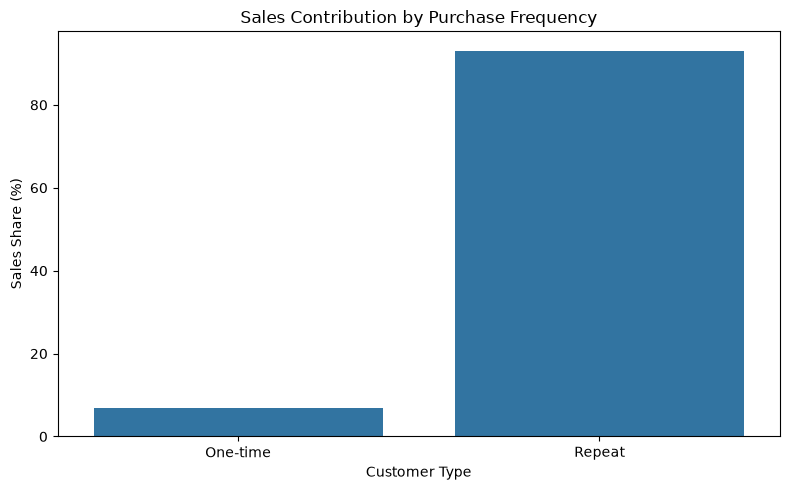

In [24]:

plot_repeat = repeat_analysis.copy()

plot_repeat.index = [
    "One-time",
    "Repeat"
]

plt.figure(figsize=(8, 5))

sns.barplot(
    x=plot_repeat.index,
    y=plot_repeat["Sales_Ratio"]
)

plt.title("Sales Contribution by Purchase Frequency")
plt.xlabel("Customer Type")
plt.ylabel("Sales Share (%)")
plt.tight_layout()
plt.show()


In [25]:

# 고객별 주문 날짜 정리
orders = rfm_data[
    ["CustomerID", "InvoiceNo", "InvoiceDate"]
].drop_duplicates(subset=["CustomerID", "InvoiceNo"])

# 주문 날짜순 정렬
orders = orders.sort_values(
    ["CustomerID", "InvoiceDate"]
)

print("전체 주문 수:", len(orders))

orders.head()


전체 주문 수: 18532


,CustomerID,InvoiceNo,InvoiceDate
36521,12346,541431,2011-01-18 10:01:00
10256,12347,537626,2010-12-07 14:57:00
42758,12347,542237,2011-01-26 14:30:00
98117,12347,549222,2011-04-07 10:43:00
152108,12347,556201,2011-06-09 13:01:00


In [26]:

# 이전 주문 날짜
orders["Previous_Date"] = (
    orders.groupby("CustomerID")["InvoiceDate"].shift(1)
)

# 이전 주문과의 시간 차이 (일 단위)
orders["Purchase_Interval"] = (
    orders["InvoiceDate"] - orders["Previous_Date"]
).dt.total_seconds() / 86400

# 구매 간격 확인
orders[
    ["CustomerID", "InvoiceDate",
     "Previous_Date", "Purchase_Interval"]
].head(10)


,CustomerID,InvoiceDate,Previous_Date,Purchase_Interval
36521,12346,2011-01-18 10:01:00,NaT,NaN
10256,12347,2010-12-07 14:57:00,NaT,NaN
42758,12347,2011-01-26 14:30:00,2010-12-07 14:57:00,49.981250
98117,12347,2011-04-07 10:43:00,2011-01-26 14:30:00,70.842361
152108,12347,2011-06-09 13:01:00,2011-04-07 10:43:00,63.095833
198239,12347,2011-08-02 08:48:00,2011-06-09 13:01:00,53.824306
311294,12347,2011-10-31 12:25:00,2011-08-02 08:48:00,90.150694
389276,12347,2011-12-07 15:52:00,2011-10-31 12:25:00,37.143750
22558,12348,2010-12-16 19:09:00,NaT,NaN
41004,12348,2011-01-25 10:42:00,2010-12-16 19:09:00,39.647917


In [27]:

# 구매 간격 통계
orders["Purchase_Interval"].describe().round(2)


count    14194.00
mean        39.97
std         51.89
min          0.00
25%          6.85
50%         21.92
75%         51.04
max        365.98
Name: Purchase_Interval, dtype: float64

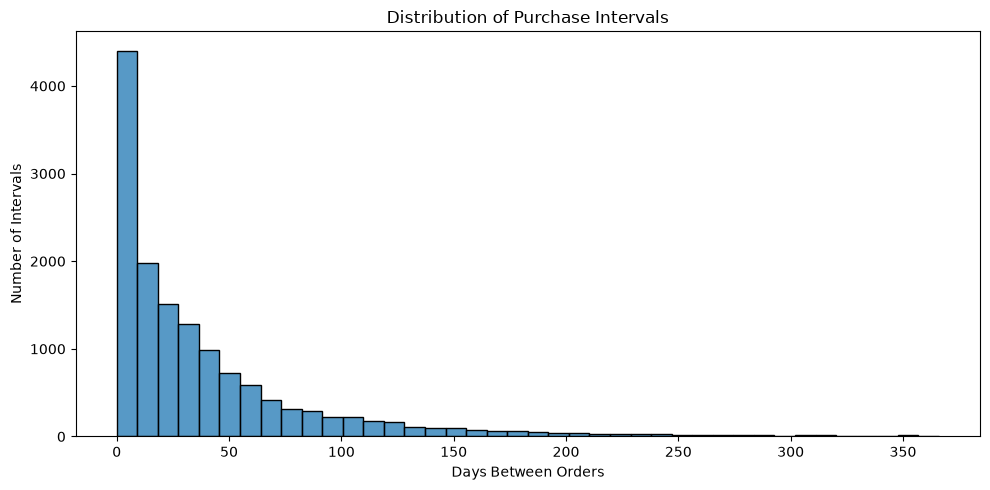

In [28]:

plt.figure(figsize=(10, 5))

sns.histplot(
    data=orders,
    x="Purchase_Interval",
    bins=40
)

plt.title("Distribution of Purchase Intervals")
plt.xlabel("Days Between Orders")
plt.ylabel("Number of Intervals")
plt.tight_layout()
plt.show()


In [29]:

# 고객별 평균 구매 간격
customer_interval = (
    orders.groupby("CustomerID")["Purchase_Interval"]
    .mean()
    .dropna()
)

# 결과 확인
customer_interval.describe().round(2)


count    2845.00
mean       72.65
std        65.56
min         0.00
25%        29.49
50%        53.46
75%        91.91
max       365.98
Name: Purchase_Interval, dtype: float64

In [30]:

# 고객별 평균 구매 간격 추가
rfm["Avg_Interval"] = customer_interval

# 결과 확인
rfm[
    ["Recency", "Frequency", "Avg_Interval"]
].head(10)


,Recency,Frequency,Avg_Interval
CustomerID,,,
12346,326,1,NaN
12347,2,7,60.839699
12348,75,4,94.250926
12349,19,1,NaN
12350,310,1,NaN
12352,36,8,37.155159
12353,204,1,NaN
12354,232,1,NaN
12355,214,1,NaN


In [31]:

# 평균 구매 간격이 0보다 큰 고객만 계산
rfm["Interval_Ratio"] = (
    rfm["Recency"] /
    rfm["Avg_Interval"].where(
        rfm["Avg_Interval"] > 0
    )
)

# 결과 확인
rfm[
    ["Recency", "Avg_Interval", "Interval_Ratio"]
].head(10)


,Recency,Avg_Interval,Interval_Ratio
CustomerID,,,
12346,326,NaN,NaN
12347,2,60.839699,0.032873
12348,75,94.250926,0.795748
12349,19,NaN,NaN
12350,310,NaN,NaN
12352,36,37.155159,0.968910
12353,204,NaN,NaN
12354,232,NaN,NaN
12355,214,NaN,NaN


In [32]:

# 평소 구매 간격의 3배 이상 미구매 고객
cycle_risk = rfm[
    (rfm["Frequency"] >= 3) &
    (rfm["Interval_Ratio"] >= 3)
].copy()

print("구매 주기 대비 장기간 미구매 고객:", len(cycle_risk))

print(
    "3회 이상 구매 고객 수:",
    (rfm["Frequency"] >= 3).sum()
)

cycle_risk[
    ["Recency", "Frequency",
     "Avg_Interval", "Interval_Ratio"]
].head(10)


구매 주기 대비 장기간 미구매 고객: 162
3회 이상 구매 고객 수: 2010


,Recency,Frequency,Avg_Interval,Interval_Ratio
CustomerID,,,,
12383,185,5,41.932986,4.411801
12414,217,3,46.500000,4.666667
12536,43,3,7.988889,5.382476
12601,190,5,35.746354,5.315227
12643,128,6,40.809444,3.136529
12722,85,4,21.707176,3.915756
12754,236,3,36.468403,6.471356
12811,261,3,11.876042,21.977020
12840,144,4,27.626852,5.212320


In [33]:

# 동일한 구매 횟수는 동일한 점수를 받도록 수정
rfm["F_Score_New"] = pd.cut(
    rfm["Frequency"],
    bins=[0, 1, 2, 4, 9, float("inf")],
    labels=[1, 2, 3, 4, 5]
).astype(int)

# 기존 점수와 새로운 점수 비교
print(
    rfm[["Frequency", "F_Score", "F_Score_New"]]
    .head(10)
)

print("새로운 F 점수 분포:")
print(rfm["F_Score_New"].value_counts().sort_index())


            Frequency  F_Score  F_Score_New
CustomerID                                 
12346               1        1            1
12347               7        5            4
12348               4        4            3
12349               1        1            1
12350               1        1            1
12352               8        5            4
12353               1        1            1
12354               1        1            1
12355               1        1            1
12356               3        3            3
새로운 F 점수 분포:
F_Score_New
1    1493
2     835
3     896
4     723
5     391
Name: count, dtype: int64


In [34]:

# 새로운 F 점수를 기존 F 점수에 적용
rfm["F_Score"] = rfm["F_Score_New"]

# RFM 총점 다시 계산
rfm["RFM_Score"] = (
    rfm["R_Score"]
    + rfm["F_Score"]
    + rfm["M_Score"]
)

# 고객 등급 다시 분류
rfm["Segment"] = rfm["RFM_Score"].apply(
    customer_segment
)

# 새로운 고객 등급별 인원 확인
print(rfm["Segment"].value_counts())


Segment
Low Activity    1522
Regular         1116
High Value       965
VIP              735
Name: count, dtype: int64


In [35]:

# 고객 등급별 고객 수와 매출 계산
segment_analysis = rfm.groupby("Segment").agg(
    Customers=("Monetary", "count"),
    Total_Sales=("Monetary", "sum"),
    Avg_Sales=("Monetary", "mean")
)

# 고객 비중 계산
segment_analysis["Customer_Ratio"] = (
    segment_analysis["Customers"]
    / segment_analysis["Customers"].sum() * 100
)

# 매출 비중 계산
segment_analysis["Sales_Ratio"] = (
    segment_analysis["Total_Sales"]
    / segment_analysis["Total_Sales"].sum() * 100
)

# 결과 확인
segment_analysis.round(2)


,Customers,Total_Sales,Avg_Sales,Customer_Ratio,Sales_Ratio
Segment,,,,,
High Value,965,1847234.20,1914.23,22.25,20.79
Low Activity,1522,451563.98,296.69,35.09,5.08
Regular,1116,1008137.91,903.35,25.73,11.34
VIP,735,5580272.80,7592.21,16.94,62.79


In [36]:

# Recency의 분위수 경계 확인
print(
    rfm["Recency"].quantile(
        [0.2, 0.4, 0.6, 0.8]
    )
)


0.2     13.4
0.4     33.0
0.6     72.0
0.8    179.0
Name: Recency, dtype: float64


In [37]:

print("기존 R 점수 분포:")

print(
    rfm["R_Score"]
    .value_counts()
    .sort_index()
)


기존 R 점수 분포:
R_Score
1    868
2    867
3    868
4    867
5    868
Name: count, dtype: int64


In [38]:

# 동일한 Recency 값에 동일한 점수 부여
rfm["R_Score_New"] = pd.cut(
    rfm["Recency"],
    bins=[0, 13, 33, 72, 179, float("inf")],
    labels=[5, 4, 3, 2, 1],
    include_lowest=True
).astype(int)

# 새로운 R 점수 분포 확인
print("새로운 R 점수 분포:")
print(
    rfm["R_Score_New"]
    .value_counts()
    .sort_index()
)


새로운 R 점수 분포:
R_Score_New
1    865
2    843
3    858
4    904
5    868
Name: count, dtype: int64


In [39]:

# 수정된 R 점수 적용
rfm["R_Score"] = rfm["R_Score_New"]

# RFM 총점 재계산
rfm["RFM_Score"] = (
    rfm["R_Score"]
    + rfm["F_Score"]
    + rfm["M_Score"]
)

# 고객 등급 다시 분류
rfm["Segment"] = rfm["RFM_Score"].apply(
    customer_segment
)

# 고객 등급별 매출 분석
segment_final = rfm.groupby("Segment").agg(
    Customers=("Monetary", "count"),
    Total_Sales=("Monetary", "sum"),
    Avg_Sales=("Monetary", "mean")
)

segment_final["Customer_Ratio"] = (
    segment_final["Customers"]
    / segment_final["Customers"].sum() * 100
)

segment_final["Sales_Ratio"] = (
    segment_final["Total_Sales"]
    / segment_final["Total_Sales"].sum() * 100
)

segment_final.round(2)


,Customers,Total_Sales,Avg_Sales,Customer_Ratio,Sales_Ratio
Segment,,,,,
High Value,965,1829968.61,1896.34,22.25,20.59
Low Activity,1513,447794.71,295.96,34.88,5.04
Regular,1119,1004660.37,897.82,25.80,11.30
VIP,741,5604785.20,7563.81,17.08,63.07


In [40]:

# 동일한 구매금액에 서로 다른 M 점수가 있는지 확인
m_check = (
    rfm.groupby("Monetary")["M_Score"]
    .nunique()
)

# 구매금액은 같지만 점수가 다른 경우
m_problem = (m_check > 1).sum()

print("M 점수 동점 처리 문제:", m_problem, "개")

# 구매금액 분위수 확인
print("\nMonetary 분위수:")
print(
    rfm["Monetary"].quantile(
        [0.2, 0.4, 0.6, 0.8]
    )
)


M 점수 동점 처리 문제: 0 개

Monetary 분위수:
0.2     249.344
0.4     487.412
0.6     933.348
0.8    2055.050
Name: Monetary, dtype: float64


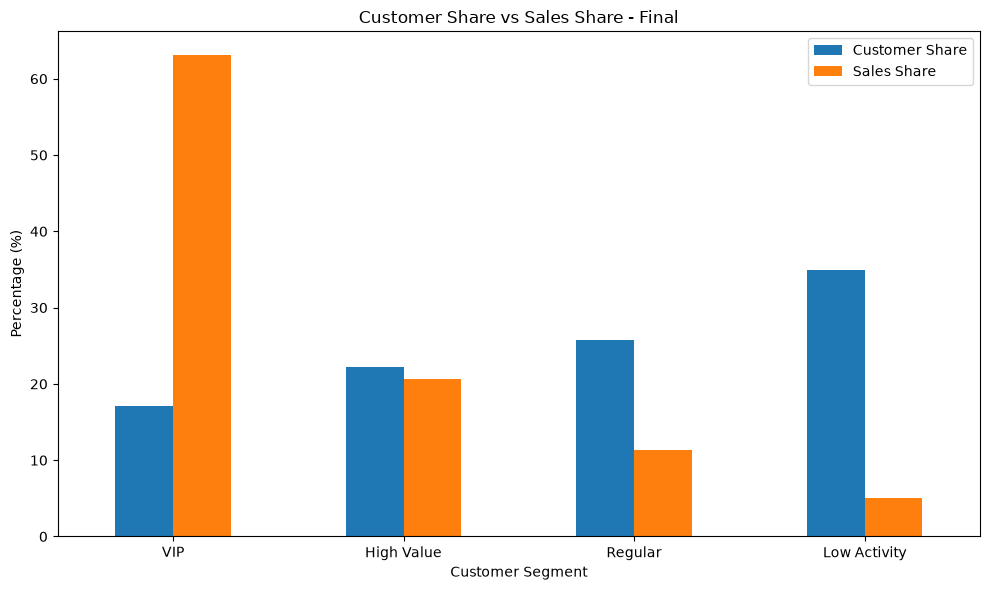

RFM 그래프 저장 완료


In [41]:

from pathlib import Path
import matplotlib.pyplot as plt

Path("output").mkdir(exist_ok=True)

# 최종 RFM 분석 결과
segment_order = [
    "VIP",
    "High Value",
    "Regular",
    "Low Activity"
]

plot_data = segment_final.loc[
    segment_order,
    ["Customer_Ratio", "Sales_Ratio"]
]

# 그래프 생성
ax = plot_data.plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("Customer Share vs Sales Share - Final")
plt.xlabel("Customer Segment")
plt.ylabel("Percentage (%)")
plt.xticks(rotation=0)
plt.legend(["Customer Share", "Sales Share"])
plt.tight_layout()

# 그래프 저장
plt.savefig(
    "output/rfm_segment_final.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("RFM 그래프 저장 완료")


In [42]:

# 고객 등급별 분석 결과 저장
segment_final.to_csv(
    "output/rfm_segment_final.csv",
    encoding="utf-8-sig"
)

print("RFM 분석표 저장 완료")


RFM 분석표 저장 완료


In [43]:

repeat_analysis.to_csv(
    "output/repeat_purchase_final.csv",
    encoding="utf-8-sig"
)

print("재구매 분석표 저장 완료")


재구매 분석표 저장 완료
